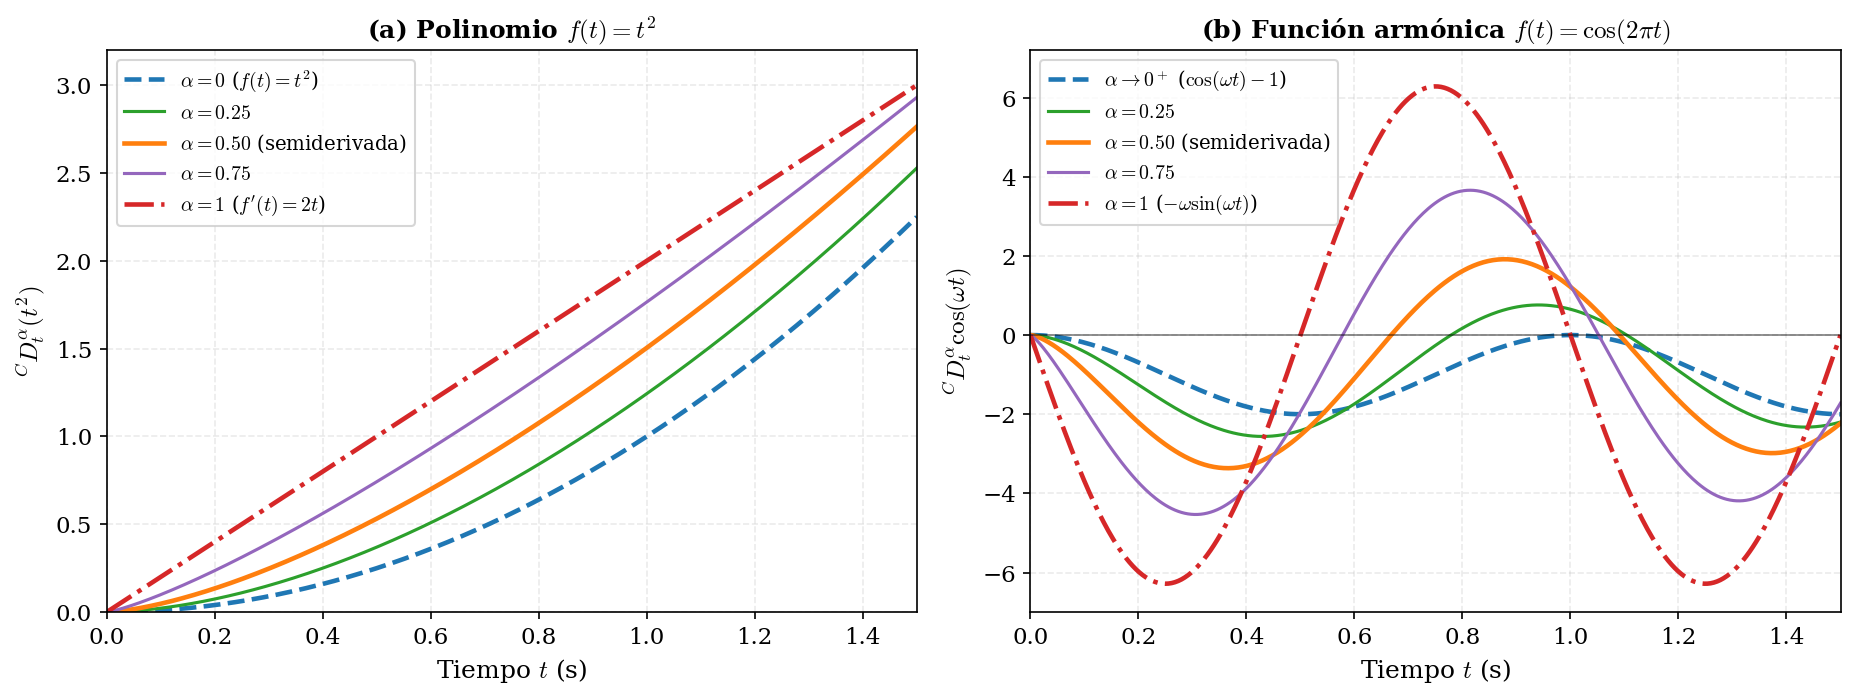

✅ Figura generada: Fig_2_1_Caputo_Polinomio_Coseno.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma

# Configuración editorial estándar (estilo APS / IEEE / Tesis UTP)
plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9.5,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

def caputo_t2(t, alpha):
    """Derivada de Caputo exacta de f(t) = t^2 para 0 <= alpha <= 1."""
    if alpha == 0.0:
        return t**2
    if alpha == 1.0:
        return 2.0 * t
    return (2.0 / gamma(3.0 - alpha)) * np.power(t, 2.0 - alpha)

def caputo_cos(t, omega, alpha, n_terms=45):
    """
    Derivada de Caputo exacta de f(t) = cos(omega * t) para 0 < alpha <= 1
    mediante serie analítica término a término (precisión de máquina en t in [0, 2]).
    """
    if alpha == 0.0:
        # Límite alpha -> 0+: cos(wt) - cos(0) debido a la anulación de constantes en Caputo
        return np.cos(omega * t) - 1.0
    if alpha == 1.0:
        return -omega * np.sin(omega * t)

    res = np.zeros_like(t, dtype=float)
    # Evitar 0^(2k - alpha) warnings
    t_safe = np.where(t == 0, 1e-15, t)
    for k in range(1, n_terms + 1):
        termino = ((-1)**k) * (omega**(2*k)) / gamma(2*k + 1.0 - alpha) * np.power(t_safe, 2*k - alpha)
        res += termino
    res[t == 0] = 0.0
    return res

# Dominios temporales
t_poly = np.linspace(0, 1.5, 400)
t_trig = np.linspace(0, 1.5, 500)
omega = 2.0 * np.pi  # f = 1 Hz (1.5 ciclos completos)

alphas = [0.0, 0.25, 0.50, 0.75, 1.0]
colores = ['#1f77b4', '#2ca02c', '#ff7f0e', '#9467bd', '#d62728']
estilos = ['--', '-', '-', '-', '-.']
etiquetas_poly = [
    r'$\alpha = 0$ ($f(t) = t^2$)',
    r'$\alpha = 0.25$',
    r'$\alpha = 0.50$ (semiderivada)',
    r'$\alpha = 0.75$',
    r'$\alpha = 1$ ($f^\prime(t) = 2t$)'
]
etiquetas_cos = [
    r'$\alpha \to 0^+$ ($\cos(\omega t) - 1$)',
    r'$\alpha = 0.25$',
    r'$\alpha = 0.50$ (semiderivada)',
    r'$\alpha = 0.75$',
    r'$\alpha = 1$ ($-\omega\sin(\omega t)$)'
]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

# Panel (a): Polinomio t^2
for a, col, ls, lab in zip(alphas, colores, estilos, etiquetas_poly):
    lw = 2.2 if a in [0.0, 0.5, 1.0] else 1.5
    ax1.plot(t_poly, caputo_t2(t_poly, a), color=col, linestyle=ls, linewidth=lw, label=lab)

ax1.set_title(r'(a) Polinomio $f(t) = t^2$', fontweight='bold')
ax1.set_xlabel(r'Tiempo $t$ (s)')
ax1.set_ylabel(r'${}^{C}D_t^\alpha (t^2)$')
ax1.set_xlim(0, 1.5)
ax1.set_ylim(0, 3.2)
ax1.legend(loc='upper left', frameon=True)

# Panel (b): Coseno cos(wt)
for a, col, ls, lab in zip(alphas, colores, estilos, etiquetas_cos):
    lw = 2.2 if a in [0.0, 0.5, 1.0] else 1.5
    ax2.plot(t_trig, caputo_cos(t_trig, omega, a), color=col, linestyle=ls, linewidth=lw, label=lab)

# Reemplaza estas líneas al final del bloque del Panel (b):
ax2.axhline(0, color='black', linewidth=0.8, alpha=0.5)
ax2.set_title(r'(b) Función armónica $f(t) = \cos(2\pi t)$', fontweight='bold')
ax2.set_xlabel(r'Tiempo $t$ (s)')
ax2.set_ylabel(r'${}^{C}D_t^\alpha \cos(\omega t)$')
ax2.set_xlim(0, 1.5)
ax2.set_ylim(-7.0, 7.2)
ax2.legend(loc='upper left', frameon=True)  # <-- Zona superior izquierda libre

plt.tight_layout()
plt.savefig('Fig_2_1_Caputo_Polinomio_Coseno.pdf', bbox_inches='tight')
plt.savefig('Fig_2_1_Caputo_Polinomio_Coseno.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura generada: Fig_2_1_Caputo_Polinomio_Coseno.pdf")

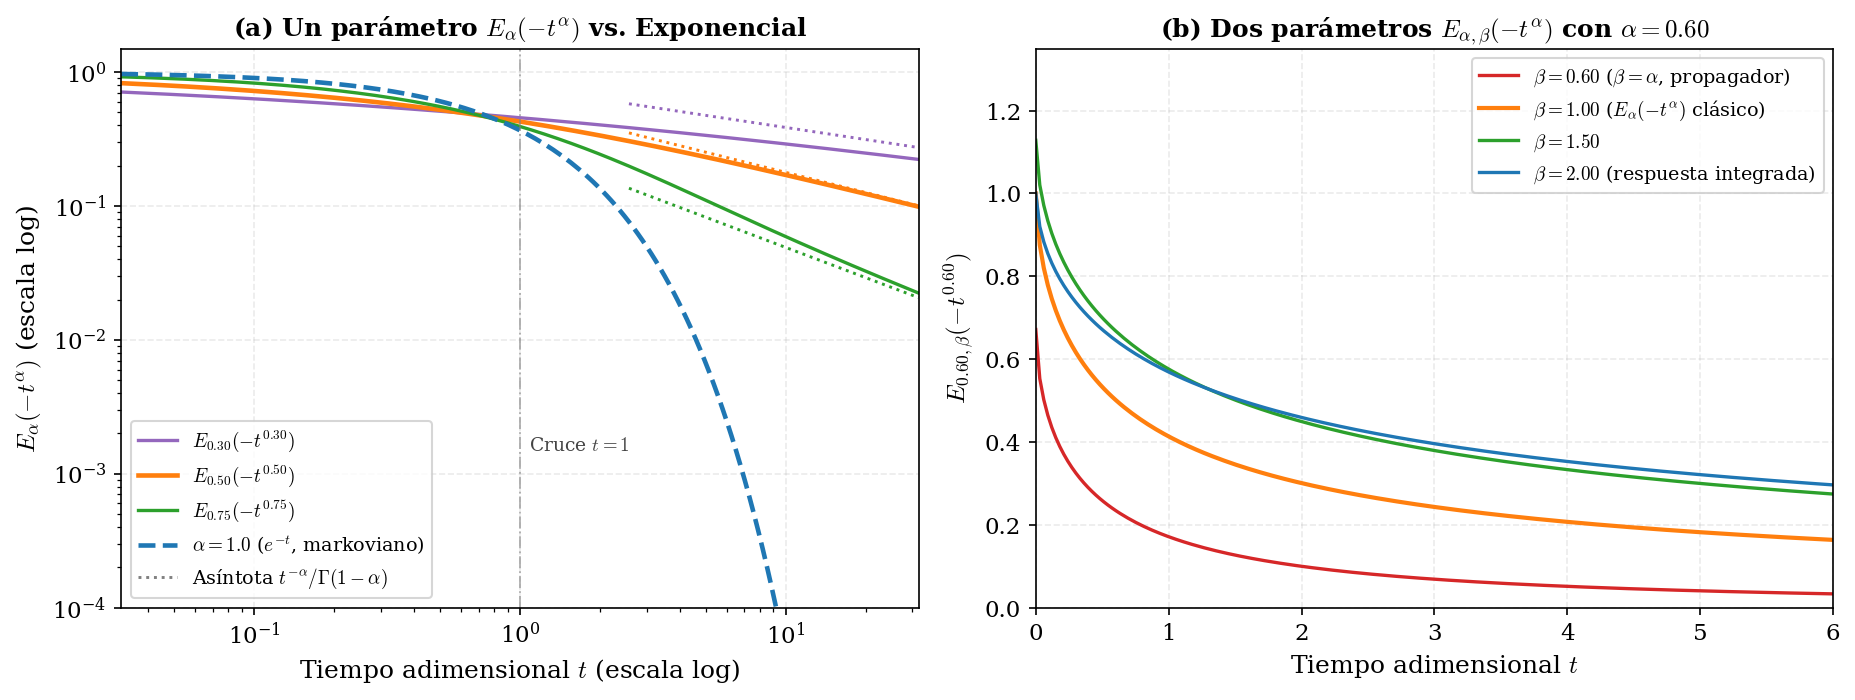

✅ Figura generada correctamente: Fig_2_2_Mittag_Leffler.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import gamma
import mpmath as mp

# 50 dígitos de precisión interna: elimina por completo la cancelación numérica en colas largas
mp.mp.dps = 80

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9.2,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

def eval_ml(alpha, beta, t_arr, max_terms=500):
    """
    Evalúa E_{alpha, beta}(-t^alpha) con 50 dígitos de precisión mediante mpmath
    usando únicamente operaciones básicas (mp.gamma y mp.power), libre de cancelación.
    """
    a_mp = mp.mpf(str(alpha))
    b_mp = mp.mpf(str(beta))
    tol = mp.mpf('1e-25')
    vals = np.zeros_like(t_arr, dtype=float)

    for i, t_val in enumerate(t_arr):
        if t_val == 0.0:
            vals[i] = float(1 / mp.gamma(b_mp))
            continue
        z = -mp.power(mp.mpf(str(t_val)), a_mp)
        suma = mp.mpf('0')
        z_pow = mp.mpf('1')
        for k in range(max_terms):
            term = z_pow / mp.gamma(a_mp * k + b_mp)
            suma += term
            if abs(term) < tol and k > 15:
                break
            z_pow *= z
        vals[i] = float(suma)
    return vals

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.8))

# -------------------------------------------------------------------------
# Panel (a): Mittag-Leffler de 1 parámetro E_alpha(-t^alpha) en Log-Log
# -------------------------------------------------------------------------
t_log = np.logspace(-1.5, 1.5, 180)  # t desde ~0.03 hasta ~31.6
alphas = [0.30, 0.50, 0.75, 1.00]
colores_a = ['#9467bd', '#ff7f0e', '#2ca02c', '#1f77b4']
estilos_a = ['-', '-', '-', '--']

for a, col, ls in zip(alphas, colores_a, estilos_a):
    if a == 1.0:
        y_ml = np.exp(-t_log)
    else:
        y_ml = eval_ml(a, 1.0, t_log)
    lab = r'$\alpha = 1.0$ ($e^{-t}$, markoviano)' if a == 1.0 else rf'$E_{{{a:.2f}}}(-t^{{{a:.2f}}})$'
    lw = 2.2 if a in [0.50, 1.00] else 1.6
    ax1.loglog(t_log, y_ml, color=col, linestyle=ls, linewidth=lw, label=lab)

    # Asíntota de Wiman t^(-alpha) / Gamma(1 - alpha) para t >= 2.5
    if a < 1.0:
        t_asymp = t_log[t_log >= 2.5]
        y_asymp = (t_asymp**(-a)) / gamma(1.0 - a)
        ax1.loglog(t_asymp, y_asymp, color=col, linestyle=':', linewidth=1.4)

ax1.loglog([], [], color='gray', linestyle=':', linewidth=1.4, label=r'Asíntota $t^{-\alpha}/\Gamma(1-\alpha)$')

ax1.axvline(1.0, color='gray', linestyle='-.', linewidth=0.9, alpha=0.6)
ax1.text(1.08, 1.5e-3, 'Cruce $t=1$', fontsize=9, color='#444444')
ax1.set_title(r'(a) Un parámetro $E_\alpha(-t^\alpha)$ vs. Exponencial', fontweight='bold')
ax1.set_xlabel(r'Tiempo adimensional $t$ (escala log)')
ax1.set_ylabel(r'$E_\alpha(-t^\alpha)$ (escala log)')
ax1.set_ylim(1e-4, 1.5)
ax1.set_xlim(t_log[0], t_log[-1])
ax1.legend(loc='lower left', frameon=True)

# -------------------------------------------------------------------------
# Panel (b): Mittag-Leffler de 2 parámetros E_{0.6, beta}(-t^0.6)
# -------------------------------------------------------------------------
t_lin = np.linspace(0.0, 6.0, 200)
alpha_fijo = 0.60
betas = [0.60, 1.00, 1.50, 2.00]
colores_b = ['#d62728', '#ff7f0e', '#2ca02c', '#1f77b4']
etiquetas_b = [
    r'$\beta = 0.60$ ($\beta = \alpha$, propagador)',
    r'$\beta = 1.00$ ($E_\alpha(-t^\alpha)$ clásico)',
    r'$\beta = 1.50$',
    r'$\beta = 2.00$ (respuesta integrada)'
]

for b, col, lab in zip(betas, colores_b, etiquetas_b):
    y_ml2 = eval_ml(alpha_fijo, b, t_lin)
    lw = 2.0 if b == 1.0 else 1.6
    ax2.plot(t_lin, y_ml2, color=col, linewidth=lw, label=lab)

ax2.set_title(r'(b) Dos parámetros $E_{\alpha,\beta}(-t^\alpha)$ con $\alpha = 0.60$', fontweight='bold')
ax2.set_xlabel(r'Tiempo adimensional $t$')
ax2.set_ylabel(r'$E_{0.60,\beta}(-t^{0.60})$')
ax2.set_xlim(0, 6.0)
ax2.set_ylim(0, 1.35)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('Fig_2_2_Mittag_Leffler.pdf', bbox_inches='tight')
plt.savefig('Fig_2_2_Mittag_Leffler.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura generada correctamente: Fig_2_2_Mittag_Leffler.pdf")

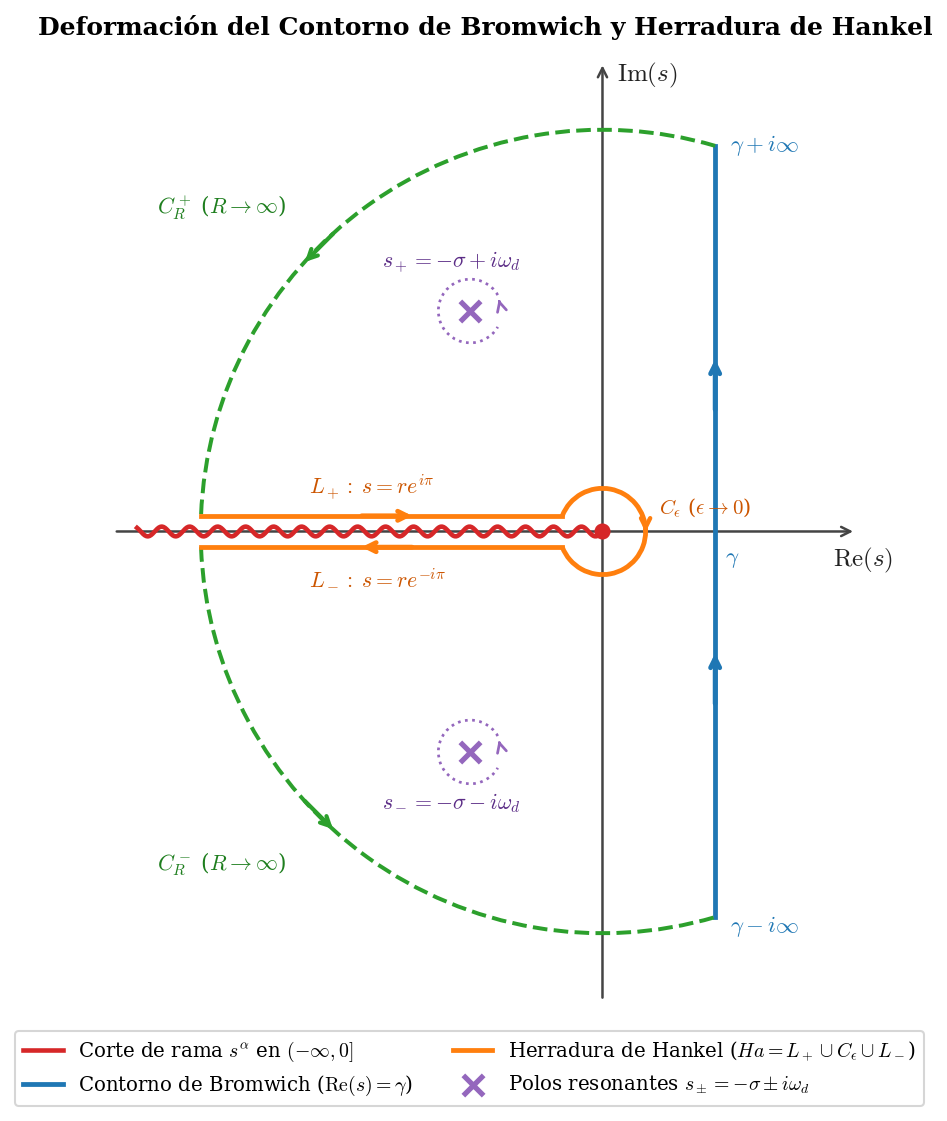

✅ Figura generada sin solapamientos: Fig_2_3_Contorno_Bromwich.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'figure.dpi': 150,
    'savefig.dpi': 300
})

fig, ax = plt.subplots(figsize=(8.0, 7.6))

# Parámetros geométricos del diagrama en el plano complejo s
R = 4.1        # Radio de los arcos exteriores C_R
gamma_x = 1.15 # Recta vertical original de Bromwich Re(s) = gamma > 0
eps = 0.44     # Radio del círculo infinitesimal C_epsilon alrededor del origen
gap = 0.16     # Separación vertical de las orillas L+ y L- respecto al corte

# 1. Ejes coordenados Re(s) e Im(s)
ax.annotate('', xy=(2.6, 0), xytext=(-5.0, 0),
            arrowprops=dict(arrowstyle='->', color='#444444', lw=1.2), zorder=1)
ax.annotate('', xy=(0, 4.8), xytext=(0, -4.8),
            arrowprops=dict(arrowstyle='->', color='#444444', lw=1.2), zorder=1)
ax.text(2.35, -0.35, r'$\mathrm{Re}(s)$', fontsize=12, fontweight='bold', color='#222222')
ax.text(0.15, 4.60, r'$\mathrm{Im}(s)$', fontsize=12, fontweight='bold', color='#222222')

# 2. Corte de rama (Branch Cut) sobre el semieje real negativo (-inf, 0]
x_cut = np.linspace(-4.75, 0, 300)
y_zig = 0.05 * np.sin(22 * x_cut)
ax.plot(x_cut, y_zig, color='#d62728', lw=2.2, zorder=4, label=r'Corte de rama $s^\alpha$ en $(-\infty, 0]$')
ax.scatter([0], [0], color='#d62728', s=45, zorder=5)

# 3. Recta original de Bromwich: Re(s) = gamma
y_max_brom = np.sqrt(R**2 - gamma_x**2)
ax.plot([gamma_x, gamma_x], [-y_max_brom, y_max_brom], color='#1f77b4', lw=2.3, zorder=3,
        label=r'Contorno de Bromwich ($\mathrm{Re}(s)=\gamma$)')
ax.annotate('', xy=(gamma_x, 1.8), xytext=(gamma_x, 1.2),
            arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=2.3))
ax.annotate('', xy=(gamma_x, -1.2), xytext=(gamma_x, -1.8),
            arrowprops=dict(arrowstyle='->', color='#1f77b4', lw=2.3))
ax.text(gamma_x + 0.15, y_max_brom - 0.05, r'$\gamma + i\infty$', color='#1f77b4', fontsize=11)
ax.text(gamma_x + 0.15, -y_max_brom - 0.15, r'$\gamma - i\infty$', color='#1f77b4', fontsize=11)
ax.text(gamma_x + 0.10, -0.32, r'$\gamma$', color='#1f77b4', fontsize=11)

# 4. Arcos exteriores C_R (Lema de Jordan)
theta_top_ini = np.degrees(np.arctan2(y_max_brom, gamma_x))
theta_top_fin = np.degrees(np.arctan2(gap, -np.sqrt(R**2 - gap**2)))
arc_top = patches.Arc((0, 0), 2*R, 2*R, angle=0, theta1=theta_top_ini, theta2=theta_top_fin,
                      color='#2ca02c', lw=1.9, ls='--', zorder=3)
ax.add_patch(arc_top)
# Flecha sobre arco superior (sentido antihorario)
ang_f1 = np.radians(135)
ax.annotate('', xy=(R*np.cos(ang_f1 + 0.06), R*np.sin(ang_f1 + 0.06)),
            xytext=(R*np.cos(ang_f1 - 0.06), R*np.sin(ang_f1 - 0.06)),
            arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=2.0))
ax.text(-4.55, 3.25, r'$C_R^+$ ($R \to \infty$)', color='#1e7e1e', fontsize=10.5)

theta_bot_ini = 360 - theta_top_fin
theta_bot_fin = 360 - theta_top_ini
arc_bot = patches.Arc((0, 0), 2*R, 2*R, angle=0, theta1=theta_bot_ini, theta2=theta_bot_fin,
                      color='#2ca02c', lw=1.9, ls='--', zorder=3)
ax.add_patch(arc_bot)
# Flecha sobre arco inferior (sentido antihorario)
ang_f2 = np.radians(225)
ax.annotate('', xy=(R*np.cos(ang_f2 + 0.06), R*np.sin(ang_f2 + 0.06)),
            xytext=(R*np.cos(ang_f2 - 0.06), R*np.sin(ang_f2 - 0.06)),
            arrowprops=dict(arrowstyle='->', color='#2ca02c', lw=2.0))
ax.text(-4.55, -3.45, r'$C_R^-$ ($R \to \infty$)', color='#1e7e1e', fontsize=10.5)

# 5. Herradura de Hankel (L+, C_epsilon, L-)
x_arc_end = -np.sqrt(R**2 - gap**2)
x_eps_start = -np.sqrt(eps**2 - gap**2)

# Orilla superior L+ (de -R a -eps)
ax.plot([x_arc_end, x_eps_start], [gap, gap], color='#ff7f0e', lw=2.3, zorder=4,
        label=r'Herradura de Hankel ($Ha = L_+ \cup C_\epsilon \cup L_-$)')
ax.annotate('', xy=(-1.9, gap), xytext=(-2.5, gap),
            arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=2.3))
ax.text(-3.0, gap + 0.22, r'$L_+:\; s = r e^{i\pi}$', color='#cc5500', fontsize=10.5)

# Círculo infinitesimal C_epsilon rodeando el origen s = 0
ang_eps = np.degrees(np.arcsin(gap / eps))
arc_eps = patches.Arc((0, 0), 2*eps, 2*eps, angle=0, theta1=-(180 - ang_eps), theta2=(180 - ang_eps),
                      color='#ff7f0e', lw=2.3, zorder=4)
ax.add_patch(arc_eps)
ax.annotate('', xy=(eps, -0.05), xytext=(eps, 0.05),
            arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=2.1))
ax.text(eps + 0.14, 0.18, r'$C_\epsilon$ ($\epsilon \to 0$)', color='#cc5500', fontsize=10)

# Orilla inferior L- (de -eps a -R)
ax.plot([x_eps_start, x_arc_end], [-gap, -gap], color='#ff7f0e', lw=2.3, zorder=4)
ax.annotate('', xy=(-2.5, -gap), xytext=(-1.9, -gap),
            arrowprops=dict(arrowstyle='->', color='#ff7f0e', lw=2.3))
ax.text(-3.0, -gap - 0.38, r'$L_-:\; s = r e^{-i\pi}$', color='#cc5500', fontsize=10.5)

# 6. Polos conjugados s_+ y s_- en el semiplano izquierdo
sigma_p = -1.35
omega_p = 2.25
ax.scatter([sigma_p, sigma_p], [omega_p, -omega_p], marker='x', s=95, linewidths=2.5, color='#9467bd', zorder=6,
           label=r'Polos resonantes $s_\pm = -\sigma \pm i\omega_d$')

for y_p, lbl, dy in [(omega_p, r'$s_+ = -\sigma + i\omega_d$', 0.45),
                     (-omega_p, r'$s_- = -\sigma - i\omega_d$', -0.58)]:
    loop = patches.Arc((sigma_p, y_p), 0.65, 0.65, angle=0, theta1=30, theta2=330,
                       color='#9467bd', lw=1.3, ls=':', zorder=5)
    ax.add_patch(loop)
    ax.annotate('', xy=(sigma_p + 0.28, y_p + 0.16), xytext=(sigma_p + 0.31, y_p + 0.05),
                arrowprops=dict(arrowstyle='->', color='#9467bd', lw=1.3))
    ax.text(sigma_p - 0.90, y_p + dy, lbl, color='#5b2c86', fontsize=10.5, fontweight='bold')

ax.set_xlim(-5.1, 2.7)
ax.set_ylim(-4.9, 4.9)
ax.set_aspect('equal')
ax.set_xticks([])
ax.set_yticks([])
for spine in ax.spines.values():
    spine.set_visible(False)

ax.set_title('Deformación del Contorno de Bromwich y Herradura de Hankel', fontweight='bold', pad=8)

# Leyenda limpia debajo del plano complejo (cero solapamiento)
ax.legend(loc='upper center', bbox_to_anchor=(0.48, -0.01), ncol=2, frameon=True, fontsize=9.5)

plt.tight_layout()
plt.savefig('Fig_2_3_Contorno_Bromwich.pdf', bbox_inches='tight')
plt.savefig('Fig_2_3_Contorno_Bromwich.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura generada sin solapamientos: Fig_2_3_Contorno_Bromwich.pdf")

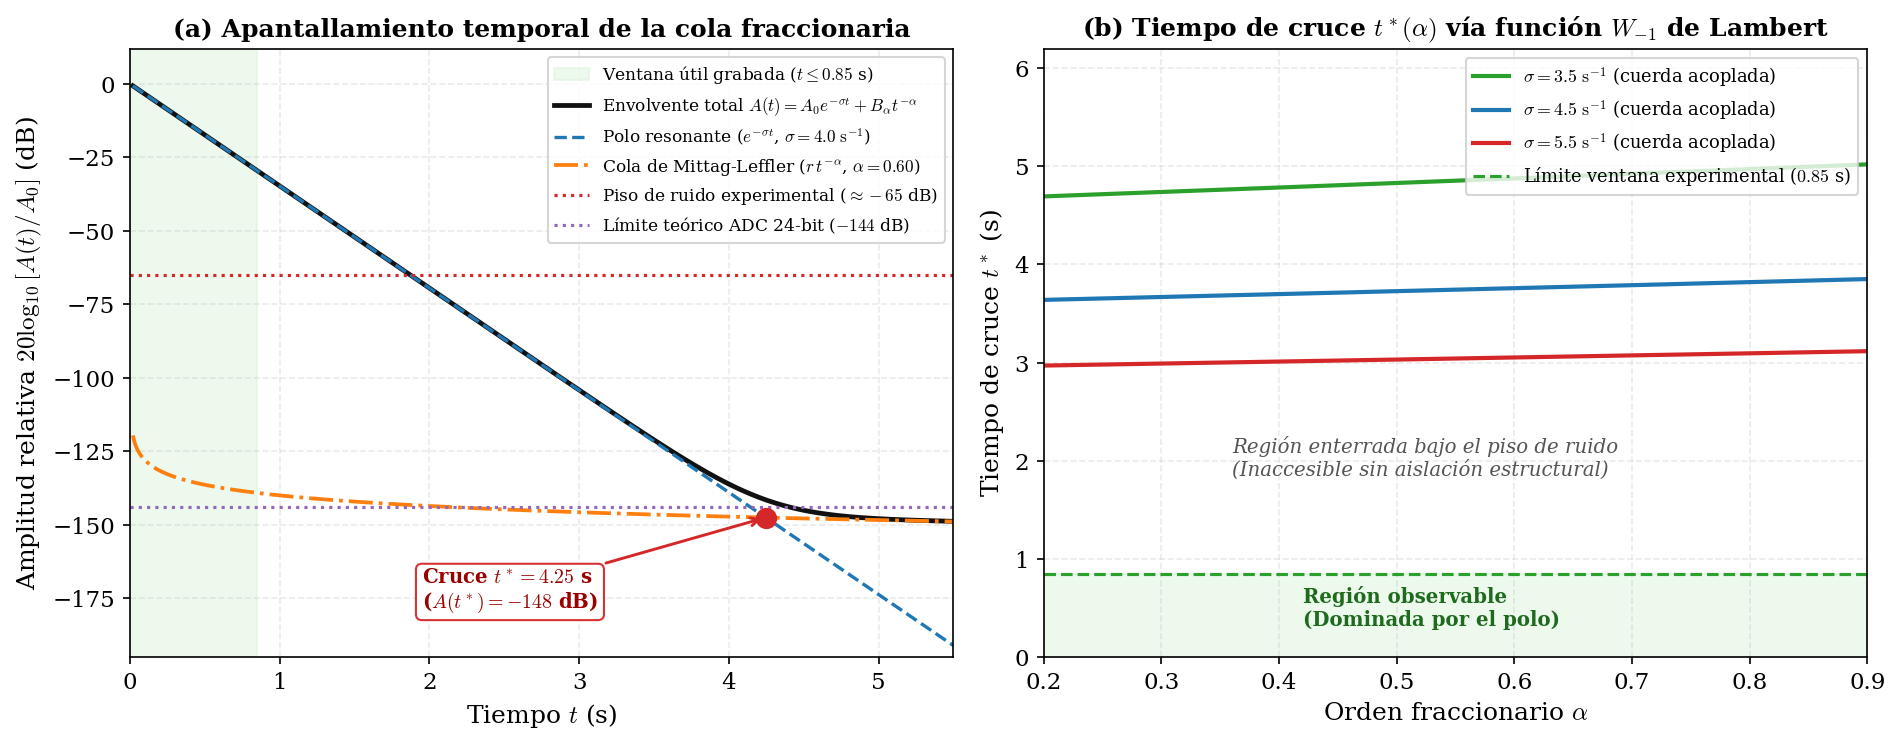

✅ Figura generada sin solapamientos: Fig_2_4_Pared_Temporal.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import lambertw

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 8.8,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

def calcular_t_star(alpha, sigma, r_bound):
    """Calcula el tiempo de cruce exacto t* usando la rama W_{-1} de Lambert."""
    arg = -(sigma / alpha) * (r_bound ** (1.0 / alpha))
    w_val = np.real(lambertw(arg, k=-1))
    return -(alpha / sigma) * w_val

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.8, 5.1))

# -------------------------------------------------------------------------
# Panel (a): Envolvente de dos escalas en dB y pisos de ruido
# -------------------------------------------------------------------------
t = np.linspace(0.02, 5.5, 500)
sigma_ej = 4.0
alpha_ej = 0.60
r_ej = 1e-7

polo = np.exp(-sigma_ej * t)
cola = r_ej * (t ** (-alpha_ej))
total = polo + cola

polo_db = 20 * np.log10(polo)
cola_db = 20 * np.log10(cola)
total_db = 20 * np.log10(total)

t_star = calcular_t_star(alpha_ej, sigma_ej, r_ej)
amp_star_db = 20 * np.log10(np.exp(-sigma_ej * t_star))

# Sombreado de la ventana experimental útil (t <= 0.85 s)
ax1.axvspan(0, 0.85, color='#d9f2d9', alpha=0.45, label=r'Ventana útil grabada ($t \leq 0.85$ s)')

ax1.plot(t, total_db, color='#111111', lw=2.3, label=r'Envolvente total $A(t) = A_0 e^{-\sigma t} + B_\alpha t^{-\alpha}$')
ax1.plot(t, polo_db, color='#1f77b4', ls='--', lw=1.6, label=r'Polo resonante ($e^{-\sigma t}$, $\sigma=4.0\ \mathrm{s}^{-1}$)')
ax1.plot(t, cola_db, color='#ff7f0e', ls='-.', lw=1.8, label=r'Cola de Mittag-Leffler ($r\,t^{-\alpha}$, $\alpha=0.60$)')

# Pisos de ruido experimental y límite ADC 24-bit
ax1.axhline(-65, color='#d62728', ls=':', lw=1.5, label=r'Piso de ruido experimental ($\approx -65$ dB)')
ax1.axhline(-144, color='#9467bd', ls=':', lw=1.5, label=r'Límite teórico ADC 24-bit ($-144$ dB)')

# Marcar el punto exacto de cruce t* (totalmente libre al mover la leyenda arriba)
ax1.scatter([t_star], [amp_star_db], color='#d62728', s=85, zorder=6)
ax1.annotate(
    rf'Cruce $t^* = {t_star:.2f}$ s' + '\n' + rf'($A(t^*) = {amp_star_db:.0f}$ dB)',
    xy=(t_star, amp_star_db), xytext=(1.95, -178),
    arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.4),
    fontsize=9.5, fontweight='bold', color='#990000',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d62728', alpha=0.95)
)

ax1.set_title('(a) Apantallamiento temporal de la cola fraccionaria', fontweight='bold')
ax1.set_xlabel(r'Tiempo $t$ (s)')
ax1.set_ylabel(r'Amplitud relativa $20\log_{10}[A(t)/A_0]$ (dB)')
ax1.set_xlim(0, 5.5)
ax1.set_ylim(-195, 12)
ax1.legend(loc='upper right', frameon=True, fontsize=8.2)  # <-- Esquina superior derecha despejada

# -------------------------------------------------------------------------
# Panel (b): Tiempo de cruce t*(alpha) para distintas tasas de amortiguamiento
# -------------------------------------------------------------------------
alpha_grid = np.linspace(0.20, 0.90, 200)
sigmas_list = [3.5, 4.5, 5.5]
colores_s = ['#2ca02c', '#1f77b4', '#d62728']

for sig, col in zip(sigmas_list, colores_s):
    t_stars = [calcular_t_star(a, sig, 1e-7) for a in alpha_grid]
    ax2.plot(alpha_grid, t_stars, color=col, lw=2.0, label=rf'$\sigma = {sig:.1f}\ \mathrm{{s}}^{{-1}}$ (cuerda acoplada)')

ax2.axhline(0.85, color='#2ca02c', ls='--', lw=1.5, label=r'Límite ventana experimental ($0.85$ s)')
ax2.fill_between(alpha_grid, 0, 0.85, color='#d9f2d9', alpha=0.45)
ax2.text(0.42, 0.32, 'Región observable\n(Dominada por el polo)', fontsize=9.5, color='#1e6b1e', fontweight='bold')
ax2.text(0.36, 1.85, 'Región enterrada bajo el piso de ruido\n(Inaccesible sin aislación estructural)',
         fontsize=9.5, color='#555555', style='italic')

ax2.set_title(r'(b) Tiempo de cruce $t^*(\alpha)$ vía función $W_{-1}$ de Lambert', fontweight='bold')
ax2.set_xlabel(r'Orden fraccionario $\alpha$')
ax2.set_ylabel(r'Tiempo de cruce $t^*$ (s)')
ax2.set_xlim(0.20, 0.90)
ax2.set_ylim(0, 6.2)  # <-- Margen superior ampliado para que la leyenda no toque la curva verde
ax2.legend(loc='upper right', frameon=True, fontsize=8.6)

plt.tight_layout()
plt.savefig('Fig_2_4_Pared_Temporal.pdf', bbox_inches='tight')
plt.savefig('Fig_2_4_Pared_Temporal.png', dpi=300, bbox_inches='tight')
plt.show()
print(f"✅ Figura generada sin solapamientos: Fig_2_4_Pared_Temporal.pdf")

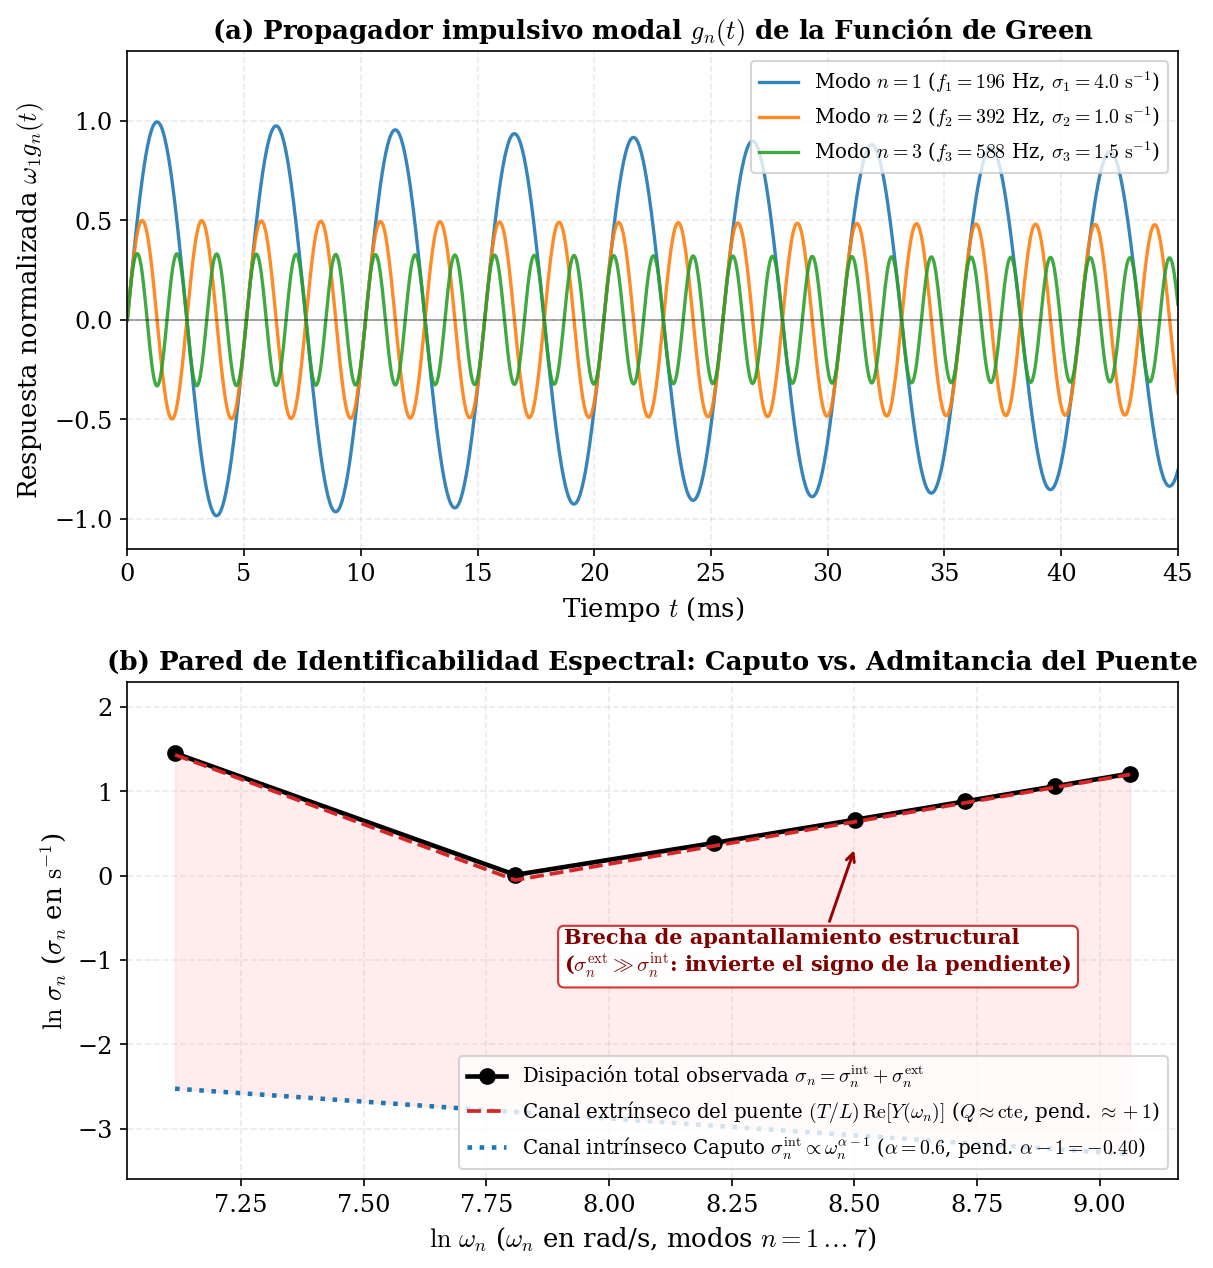

✅ Figura generada con tipografía legible: Fig_3_1_Green_Pared_Espectral.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11.5,
    'axes.labelsize': 12.5,
    'axes.titlesize': 12.5,
    'legend.fontsize': 9.5,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.2, 8.6))

# -------------------------------------------------------------------------
# Panel (a): Propagadores impulsivos modales g_n(t) para n = 1, 2, 3
# -------------------------------------------------------------------------
t = np.linspace(0, 0.045, 1200)  # Primeros 45 ms para apreciar oscilación y envolvente
f1 = 196.0
modos = [1, 2, 3]
sigmas_mod = [4.0, 1.0, 1.5]  # Tasas experimentales características G3
colores_m = ['#1f77b4', '#ff7f0e', '#2ca02c']

for n, sig, col in zip(modos, sigmas_mod, colores_m):
    fn = n * f1
    wn = 2 * np.pi * fn
    wd = np.sqrt(wn**2 - sig**2)
    # Normalizado por w_1 para comparar amplitudes relativas en una misma escala
    gn = (2 * np.pi * f1 / wd) * np.exp(-sig * t) * np.sin(wd * t)
    ax1.plot(t * 1000, gn, color=col, lw=1.6, alpha=0.9,
             label=rf'Modo $n={n}$ ($f_{n}={fn:.0f}$ Hz, $\sigma_{n}={sig:.1f}\ \mathrm{{s}}^{{-1}}$)')

ax1.axhline(0, color='black', lw=0.8, alpha=0.4)
ax1.set_title(r'(a) Propagador impulsivo modal $g_n(t)$ de la Función de Green', fontweight='bold')
ax1.set_xlabel(r'Tiempo $t$ (ms)')
ax1.set_ylabel(r'Respuesta normalizada $\omega_1 g_n(t)$')
ax1.set_xlim(0, 45)
ax1.set_ylim(-1.15, 1.35)
ax1.legend(loc='upper right', ncol=1, frameon=True)

# -------------------------------------------------------------------------
# Panel (b): La Pared de Identificabilidad Espectral (ln sigma_n vs ln omega_n)
# -------------------------------------------------------------------------
n_arr = np.arange(1, 8)
omega_arr = 2 * np.pi * f1 * n_arr
ln_w = np.log(omega_arr)

# 1. Canal intrínseco puro de Caputo (aislado): sigma_int ~ omega^(alpha - 1)
alpha_test = 0.60
# Escala física realista (1 a 2 órdenes de magnitud por debajo del puente)
sigma_int = 0.08 * ((omega_arr / omega_arr[0]) ** (alpha_test - 1.0))

# 2. Canal extrínseco del puente (ley de Q constante + pico lobo en n=1)
sigma_ext = 0.95 * (omega_arr / omega_arr[1])
sigma_ext[0] = 4.2  # Acoplamiento resonante del fundamental con la tapa (lobo)
sigma_total = sigma_int + sigma_ext

ax2.plot(ln_w, np.log(sigma_total), 'ko-', lw=2.2, markersize=7,
         label=r'Disipación total observada $\sigma_n = \sigma_n^{\mathrm{int}} + \sigma_n^{\mathrm{ext}}$')
ax2.plot(ln_w, np.log(sigma_ext), color='#d62728', ls='--', lw=1.8,
         label=r'Canal extrínseco del puente $(T/L)\,\mathrm{Re}[Y(\omega_n)]$ ($Q \approx \mathrm{cte}$, pend. $\approx +1$)')
ax2.plot(ln_w, np.log(sigma_int), color='#1f77b4', ls=':', lw=2.2,
         label=rf'Canal intrínseco Caputo $\sigma_n^{{\mathrm{{int}}}} \propto \omega_n^{{\alpha-1}}$ ($\alpha={alpha_test}$, pend. $\alpha-1 = {alpha_test-1:.2f}$)')

# Sombreado de la brecha de apantallamiento
ax2.fill_between(ln_w, np.log(sigma_int), np.log(sigma_total), color='#ffcccc', alpha=0.35)
ax2.annotate(
    'Brecha de apantallamiento estructural\n'
    r'($\sigma_n^{\mathrm{ext}} \gg \sigma_n^{\mathrm{int}}$: invierte el signo de la pendiente)',
    xy=(ln_w[3], 0.35), xytext=(ln_w[1] + 0.1, -1.15),
    arrowprops=dict(arrowstyle='->', color='#990000', lw=1.4),
    fontsize=10, fontweight='bold', color='#800000',
    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d62728', alpha=0.95)
)

ax2.set_title(r'(b) Pared de Identificabilidad Espectral: Caputo vs. Admitancia del Puente', fontweight='bold')
ax2.set_xlabel(r'$\ln\,\omega_n$ ($\omega_n$ en rad/s, modos $n=1\dots 7$)')
ax2.set_ylabel(r'$\ln\,\sigma_n$ ($\sigma_n$ en $\mathrm{s}^{-1}$)')
ax2.set_ylim(-3.6, 2.3)
ax2.legend(loc='lower right', frameon=True)

plt.tight_layout()
plt.savefig('Fig_3_1_Green_Pared_Espectral.pdf', bbox_inches='tight')
plt.savefig('Fig_3_1_Green_Pared_Espectral.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura generada con tipografía legible: Fig_3_1_Green_Pared_Espectral.pdf")

In [ ]:
import nbformat as nbf
from google.colab import files

nb = nbf.v4.new_notebook()

# -------------------------------------------------------------------------
# CELDA 1: Markdown Introductorio
# -------------------------------------------------------------------------
md_intro = r"""# 📘 AUDITORÍA DE IDENTIFICABILIDAD EN VENTANA EXTENDIDA (DATASET D2)
## Prueba Directa de la Pared Temporal: 12 Archivos de Evento Único (Diseño Factorial 2×2)

### Protocolo Pre-registrado (Antes de inspeccionar los datos)
A diferencia del Dataset D1 (4 archivos con 5 pulsaciones concatenadas de $0.80\text{–}0.99\text{ s}$), el **Dataset D2** consta de **12 grabaciones independientes** (3 repeticiones por condición) donde la cuerda Sol ($G_3, f_0 \approx 196\text{ Hz}$) se pulsa una única vez y se deja decaer libremente hasta extinguirse en el piso de ruido:
* **XLR** $\rightarrow$ Captación por micrófono (`dedo` / `púa`, 3 archivos c/u).
* **Jack** $\rightarrow$ Captación por línea piezoeléctrica (`dedo` / `púa`, 3 archivos c/u).

### Criterios de Decisión Pre-registrados (Rama A vs. Rama B)
1. **Rama A (Confirmación de Pared Temporal en ventana extendida):** Al extender la ventana de observación más allá de $1\text{ s}$, $\beta_{\text{eff}}(t) = -t\,\frac{d\ln A}{dt}$ sigue la rampa exponencial $\sigma t$ y colapsa hacia $\beta_{\text{eff}} \approx 0$ al tocar el piso de ruido ambiental, sin estabilizarse en ninguna meseta fraccionaria $\alpha \in (0, 1)$.
2. **Rama B (Resultado positivo de cola):** Aparece una meseta estable (plateau con $\text{IQR} < 0.25$) en $\beta_{\text{eff}}(t) \in (0.1, 0.9)$ por encima del piso de ruido antes de la extinción, obligando a revisar la cota teórica $r = B_\alpha/A_0 \lesssim 10^{-7}$."""

# -------------------------------------------------------------------------
# CELDA 2: Código de Carga e Integridad
# -------------------------------------------------------------------------
code_carga = r"""import os
import warnings
import numpy as np
import pandas as pd
import scipy
from scipy import signal
import librosa
import matplotlib.pyplot as plt

warnings.filterwarnings('ignore')

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9.0,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

print('✅ Entorno configurado para Auditoría D2 (Ventana Extendida).')
print(f' - NumPy v{np.__version__} | SciPy v{scipy.__version__} | Librosa v{librosa.__version__}\n')

# Carga de los 12 archivos WAV del Dataset D2
archivos_wav = sorted([f for f in os.listdir('.') if f.lower().endswith('.wav') and ('xlr' in f.lower() or 'jack' in f.lower())])

if len(archivos_wav) < 12:
    try:
        from google.colab import files
        print('📂 Sube los 12 archivos .wav del Dataset D2 (XLR/Jack, dedo/pua):')
        uploaded = files.upload()
        archivos_wav = sorted(list(uploaded.keys()))
    except ImportError:
        pass

def clasificar_condicion(nombre_archivo):
    low = nombre_archivo.lower()
    captacion = 'mic' if 'xlr' in low else ('linea' if 'jack' in low else 'desconocido')
    excitacion = 'pua' if 'pua' in low else ('dedo' if 'dedo' in low else 'desconocido')
    return f'{excitacion}_{captacion}', excitacion, captacion

datos_d2 = {}
print(f'\n🔄 Verificando integridad de {len(archivos_wav)} archivos (Regla R-N3: Duración real)...')
print('='*90)
for nombre in archivos_wav:
    y, sr = librosa.load(nombre, sr=None, mono=True)
    cond, exc, cap = clasificar_condicion(nombre)
    dur_total = len(y) / sr
    datos_d2[nombre] = {
        'senal': y,
        'sr': sr,
        'condicion': cond,
        'excitacion': exc,
        'captacion': cap,
        'duracion_archivo': dur_total
    }
    print(f' ✅ {nombre:20s} | Cond: {cond:10s} | fs: {sr} Hz | Duración archivo: {dur_total:5.2f} s | Muestras: {len(y)}')"""

# -------------------------------------------------------------------------
# CELDA 3: Markdown Segmentación
# -------------------------------------------------------------------------
md_seg = r"""---
# ✂️ Sección 1: Filtrado Fundamental ($196\text{ Hz}$) y Segmentación de Evento Único Extendido

A diferencia de D1, aquí **no truncamos el segmento a $0.80\text{ s}$**. Detectamos el único ataque principal del archivo, medimos el piso de ruido ambiental estrictamente **antes** del impacto (Regla **R-N4**), descartamos los primeros $50\text{ ms}$ de transitorio no lineal y dejamos correr la ventana hasta que la envolvente alcanza $2.5\times$ el piso de ruido de banda (o el final de la grabación), imprimiendo la duración real resultante (**R-N3**)."""

# -------------------------------------------------------------------------
# CELDA 4: Código Segmentación
# -------------------------------------------------------------------------
code_seg = r"""def disenar_filtro_sos(f_central, bw, fs, orden=2):
    nyq = 0.5 * fs
    low = max((f_central - bw / 2.0) / nyq, 0.001)
    high = min((f_central + bw / 2.0) / nyq, 0.999)
    return signal.butter(orden, [low, high], btype='bandpass', output='sos')

F0_SOL = 196.0
BW_FUND = 20.0  # [186 Hz, 206 Hz]

eventos_d2 = {}
print('🚀 SEGMENTACIÓN DE EVENTO ÚNICO Y AUDITORÍA DE DURACIÓN ÚTIL / SNR VERDADERO (R-N3, R-N4)')
print('='*96)

for nombre, info in datos_d2.items():
    y = info['senal']
    sr = info['sr']
    sos = disenar_filtro_sos(F0_SOL, BW_FUND, sr, orden=2)
    y_filt = signal.sosfiltfilt(sos, y)

    # Envolvente RMS suave (20 ms) para localizar el único ataque principal
    win_samples = int(0.02 * sr)
    rms_env = np.sqrt(np.convolve(y_filt**2, np.ones(win_samples)/win_samples, mode='same'))
    pk = int(np.argmax(rms_env))
    pico_val = rms_env[pk]

    # Piso de ruido PRE-ATAQUE (desde 0.10 s hasta 0.15 s antes del pico)
    pre_ini = int(0.10 * sr)
    pre_fin = max(int(0.25 * sr), pk - int(0.15 * sr))
    if pre_fin <= pre_ini:
        ruido_pre_rms = np.sqrt(np.mean(y_filt[-int(0.30*sr):]**2)) + 1e-12
    else:
        ruido_pre_rms = np.sqrt(np.mean(y_filt[pre_ini:pre_fin]**2)) + 1e-12

    # Inicio tras 50 ms de ataque; fin extendido hasta alcanzar piso de ruido (2.5x RMS pre-ataque)
    inicio = pk + int(0.05 * sr)
    limite_archivo = len(y_filt) - int(0.05 * sr)
    env_post = rms_env[inicio:limite_archivo]

    umbral_ruido = 2.5 * ruido_pre_rms
    cruce_ruido = np.where(env_post < umbral_ruido)[0]

    if len(cruce_ruido) > 0:
        fin_util = inicio + cruce_ruido[0]
        motivo_corte = 'Alcanzó piso de ruido'
    else:
        fin_util = limite_archivo
        motivo_corte = 'Fin de grabación'

    # Ventana ampliada (+1.5 s extra sobre el piso de ruido) para ver el colapso de beta_eff -> 0
    fin_extendido = min(fin_util + int(1.5 * sr), limite_archivo)

    snr_true = 20 * np.log10((pico_val + 1e-12) / ruido_pre_rms)
    dur_util = (fin_util - inicio) / sr
    dur_ext = (fin_extendido - inicio) / sr

    # Hilbert sobre la ventana extendida
    seg_ext = y_filt[inicio:fin_extendido]
    env_hilbert = np.abs(signal.hilbert(seg_ext))
    n_cut = int(0.03 * sr)
    env_clean = env_hilbert[n_cut:-n_cut]
    t_clean = np.arange(len(env_clean)) / sr + 0.05 + 0.03

    # Estimación de tau y Bedrosian eta en la zona útil
    n_util_clean = max(int((dur_util - 0.06) * sr), int(0.3 * sr))
    n_util_clean = min(n_util_clean, len(env_clean))
    p_exp, _ = np.polyfit(t_clean[:n_util_clean], np.log(env_clean[:n_util_clean] + 1e-12), 1)
    sigma_est = max(-p_exp, 0.1)
    tau_est = 1.0 / sigma_est
    eta_tau = F0_SOL * tau_est

    eventos_d2[nombre] = {
        'condicion': info['condicion'],
        'y_filt': y_filt,
        'sr': sr,
        't_ataque': pk / sr,
        'inicio_idx': inicio,
        'fin_util_idx': fin_util,
        'dur_archivo': info['duracion_archivo'],
        'dur_util': dur_util,
        'dur_ext': dur_ext,
        'ruido_pre_rms': ruido_pre_rms,
        'snr_true_db': snr_true,
        'sigma_util': sigma_est,
        'eta_tau': eta_tau,
        't_ext': t_clean,
        'env_ext': env_clean,
        'n_util_clean': n_util_clean
    }
    print(f"📁 {nombre:20s} [{info['condicion']:10s}] | File: {info['duracion_archivo']:5.2f}s | "
          f"Decaim. útil: {dur_util:5.2f}s (Ext: {dur_ext:5.2f}s) | SNR_true: {snr_true:4.1f}dB | η: {eta_tau:4.1f} ({motivo_corte})")"""

# -------------------------------------------------------------------------
# CELDA 5: Markdown beta_eff
# -------------------------------------------------------------------------
md_beta = r"""---
# 🧱 Sección 2: Evolución de $\beta_{\text{eff}}(t)$ en Todo el Decaimiento y Veredicto Rama A vs. Rama B

Evaluamos la derivada logarítmica instantánea $\beta_{\text{eff}}(t) = -t\,\frac{d\ln A(t)}{dt}$ a lo largo de **toda** la ventana extendida, reportando la **mediana e IQR** (Regla **R-N1**) en tres tramos temporales:
* **Tramo Temprano ($0.15\text{–}0.65\text{ s}$):** Régimen equivalente a D1.
* **Tramo Extendido ($0.65\text{ s} \to t_{\text{ruido}}$):** Ventana ganada gracias al protocolo de evento único D2.
* **Tramo Final / Piso de Ruido ($> t_{\text{ruido}}$):** Donde la señal queda dominada por ruido estacionario ($\beta_{\text{eff}} \to 0$)."""

# -------------------------------------------------------------------------
# CELDA 6: Código beta_eff y Gráfica
# -------------------------------------------------------------------------
code_beta = r"""filas_d2 = []
print('🔬 EVALUACIÓN DE β_eff(t) EN VENTANA EXTENDIDA (REGLA R-N1: MEDIANA E IQR)')
print('='*98)

fig, axes = plt.subplots(2, 2, figsize=(13, 8.5), sharex=True)
axes = axes.flatten()
condiciones_orden = ['dedo_linea', 'dedo_mic', 'pua_linea', 'pua_mic']
colores_rep = ['#1f77b4', '#ff7f0e', '#2ca02c']

for nombre, ev in eventos_d2.items():
    sr = ev['sr']
    t = ev['t_ext']
    env = ev['env_ext']
    log_env = np.log(env + 1e-12)

    # Suavizado Savitzky-Golay (ventana 90 ms) para filtrar el batido de ~8 Hz sin destruir tendencia
    win_sg = min(int(0.09 * sr) | 1, len(log_env) - 2)
    dlogA_dt = signal.savgol_filter(log_env, window_length=win_sg, polyorder=2, deriv=1, delta=1.0/sr)
    beta_eff = -t * dlogA_dt
    ev['beta_eff'] = beta_eff

    # Comparación EXP vs POT en toda la ventana útil (Regla R-N2: razón de RSS)
    nu = ev['n_util_clean']
    t_u, le_u = t[:nu], log_env[:nu]
    rss_exp = np.sum((le_u - np.polyval(np.polyfit(t_u, le_u, 1), t_u))**2)
    rss_pot = np.sum((le_u - np.polyval(np.polyfit(np.log(t_u), le_u, 1), np.log(t_u)))**2)
    razon_rss = rss_pot / (rss_exp + 1e-12)

    # Estadísticos robustos (Mediana e IQR) por tramo temporal (R-N1)
    m_temprano = (t >= 0.15) & (t <= 0.65)
    m_extendido = (t > 0.65) & (t <= ev['dur_util'])
    m_ruido = (t > ev['dur_util'])

    b_temp_med = np.median(beta_eff[m_temprano]) if np.any(m_temprano) else np.nan
    b_temp_iqr = (np.percentile(beta_eff[m_temprano], 75) - np.percentile(beta_eff[m_temprano], 25)) if np.any(m_temprano) else np.nan

    b_ext_med = np.median(beta_eff[m_extendido]) if np.any(m_extendido) else np.nan
    b_ext_iqr = (np.percentile(beta_eff[m_extendido], 75) - np.percentile(beta_eff[m_extendido], 25)) if np.any(m_extendido) else np.nan

    b_ruido_med = np.median(beta_eff[m_ruido]) if np.any(m_ruido) else np.nan

    # Criterio automático Rama A vs Rama B
    es_meseta_frac = (0.10 <= b_ext_med <= 0.90) and (b_ext_iqr < 0.25) and (razon_rss < 0.8)
    veredicto = 'RAMA B (Posible meseta)' if es_meseta_frac else 'RAMA A (Pared Temporal confirmada)'

    filas_d2.append({
        'archivo': nombre,
        'condicion': ev['condicion'],
        'dur_archivo_s': ev['dur_archivo'],
        'dur_util_s': ev['dur_util'],
        'SNR_true_dB': ev['snr_true_db'],
        'sigma_s_inv': ev['sigma_util'],
        'RSS_POT_sobre_RSS_EXP': razon_rss,
        'beta_temprano_med': b_temp_med,
        'beta_temprano_IQR': b_temp_iqr,
        'beta_extendido_med': b_ext_med,
        'beta_extendido_IQR': b_ext_iqr,
        'beta_piso_ruido_med': b_ruido_med,
        'veredicto': veredicto
    })
    print(f"{nombre:20s} | σ={ev['sigma_util']:4.2f}s⁻¹ | RSS_POT/EXP={razon_rss:5.2f} | "
          f"β_ext(0.65s..t_ruido)={b_ext_med:4.2f} (IQR {b_ext_iqr:4.2f}) | β_ruido={b_ruido_med:4.2f} -> {veredicto}")

# Graficar las 4 condiciones del diseño 2x2
for idx_c, cond in enumerate(condiciones_orden):
    ax = axes[idx_c]
    evs_cond = [v for v in eventos_d2.values() if v['condicion'] == cond]
    for r_i, ev in enumerate(evs_cond):
        lbl = rf'Toma {r_i+1} ($t_{{\mathrm{{útil}}}}={ev["dur_util"]:.2f}$ s, $\sigma={ev["sigma_util"]:.2f}\ \mathrm{{s}}^{{-1}}$)'
        ax.plot(ev['t_ext'], ev['beta_eff'], color=colores_rep[r_i], lw=1.4, alpha=0.85, label=lbl)
        ax.axvline(ev['dur_util'], color=colores_rep[r_i], ls=':', lw=1.1, alpha=0.7)
    ax.axhspan(0.1, 0.9, color='#d9f2d9', alpha=0.45, label=r'Banda meseta Caputo $\alpha \in (0.1, 0.9)$')
    ax.axhline(0, color='black', lw=0.8, alpha=0.5)
    ax.set_title(f'Condición D2: {cond}', fontweight='bold')
    ax.set_ylabel(r'$\beta_{\mathrm{eff}}(t) = -t\,\frac{d\ln A}{dt}$')
    ax.set_ylim(-1.0, 9.5)
    ax.legend(loc='upper right', fontsize=8.2, frameon=True)

for ax in axes[2:]:
    ax.set_xlabel('Tiempo desde el ataque $t$ (s)')

plt.suptitle(r'Dataset D2 (Ventana Extendida): Evolución de $\beta_{\mathrm{eff}}(t)$ hasta el Piso de Ruido (Líneas Punteadas)', y=1.01, fontweight='bold')
plt.tight_layout()
plt.savefig('Fig_D2_beta_eff_Ventana_Extendida.pdf', bbox_inches='tight')
plt.show()

df_d2 = pd.DataFrame(filas_d2)
df_d2.to_csv('D2_auditoria_ventana_extendida.csv', index=False)
print('\n💾 Exportado: D2_auditoria_ventana_extendida.csv y Fig_D2_beta_eff_Ventana_Extendida.pdf')"""

# -------------------------------------------------------------------------
# CELDA 7: Markdown Ruta R1
# -------------------------------------------------------------------------
md_r1 = r"""---
# 🎸 Sección 3: Espectroscopía Modal (Ruta R1) sobre el Dataset D2 ($n = 1\dots 6$)

Extracción de las tasas modales $\sigma_n$ mediante **mediana e IQR** (Regla **R-N1**), verificación de $\text{SNR}_{\text{true}} \ge 20\text{ dB}$ contra el piso de ruido pre-ataque de cada banda armónica (**R-N4**) y separación $\eta_n$ de Bedrosian, invirtiendo $\sigma_n = (T/L)\,\text{Re}[Y(\omega_n)]$ ($T/L = 107.7\text{ kg/s}^2$) para contrastar la reproducibilidad de la admitancia del puente entre **D1** y **D2**."""

# -------------------------------------------------------------------------
# CELDA 8: Código Ruta R1
# -------------------------------------------------------------------------
code_r1 = r"""T_SOBRE_L = 107.7
ARMONICOS = [1, 2, 3, 4, 5, 6]

filas_r1_d2 = []
print('🎵 RUTA R1 EN DATASET D2: TASAS MODALES σ_n, SNR_true, η Y ADMITANCIA Re[Y(ω_n)]')
print('='*96)

for nombre, info in datos_d2.items():
    y = info['senal']
    sr = info['sr']
    ev = eventos_d2[nombre]
    pk = int(ev['t_ataque'] * sr)
    inicio = ev['inicio_idx']
    fin_util = ev['fin_util_idx']

    for n in ARMONICOS:
        fn = n * F0_SOL
        omega_n = 2 * np.pi * fn
        sos_n = disenar_filtro_sos(fn, BW_FUND, sr, orden=2)
        y_n = signal.sosfiltfilt(sos_n, y)

        # Piso de ruido pre-ataque en la banda del armónico n (R-N4)
        pre_ini = int(0.10 * sr)
        pre_fin = max(int(0.25 * sr), pk - int(0.15 * sr))
        if pre_fin <= pre_ini:
            ruido_n = np.sqrt(np.mean(y_n[-int(0.30*sr):]**2)) + 1e-12
        else:
            ruido_n = np.sqrt(np.mean(y_n[pre_ini:pre_fin]**2)) + 1e-12

        seg_n = y_n[inicio:fin_util]
        env_n = np.abs(signal.hilbert(seg_n))
        corte = int(0.03 * sr)
        env_n_clean = env_n[corte:-corte]
        t_n_clean = np.arange(len(env_n_clean)) / sr

        pico_n = np.max(env_n_clean)
        snr_true_n = 20 * np.log10((pico_n + 1e-12) / ruido_n)

        # Ajuste sobre tramo por encima de 3x piso de ruido de banda
        mask_util = env_n_clean > max(3.0 * ruido_n, 0.05 * pico_n)
        if np.sum(mask_util) > int(0.15 * sr):
            p_fit = np.polyfit(t_n_clean[mask_util], np.log(env_n_clean[mask_util] + 1e-12), 1)
        else:
            p_fit = np.polyfit(t_n_clean, np.log(env_n_clean + 1e-12), 1)
        sigma_val = max(-p_fit[0], 0.05)
        eta_n = fn / sigma_val

        filas_r1_d2.append({
            'archivo': nombre,
            'condicion': info['condicion'],
            'armonico': n,
            'frecuencia_Hz': fn,
            'ln_omega_n': np.log(omega_n),
            'sigma_n': sigma_val,
            'Q_n': omega_n / (2.0 * sigma_val),
            'Re_Y_m_Ns': sigma_val / T_SOBRE_L,
            'SNR_true_dB': snr_true_n,
            'eta_Bedrosian': eta_n,
            'valido_Go': (snr_true_n >= 20.0) and (eta_n >= 10.0)
        })

df_r1_d2 = pd.DataFrame(filas_r1_d2)

resumen_r1 = df_r1_d2.groupby(['condicion', 'armonico']).agg(
    ln_omega_n=('ln_omega_n', 'first'),
    sigma_mediana=('sigma_n', 'median'),
    sigma_IQR=('sigma_n', lambda x: np.percentile(x, 75) - np.percentile(x, 25)),
    Re_Y_mediana=('Re_Y_m_Ns', 'median'),
    SNR_mediana=('SNR_true_dB', 'median'),
    eta_mediana=('eta_Bedrosian', 'median')
).reset_index()

for cond, grp in resumen_r1.groupby('condicion'):
    print(f'\n📊 Condición D2: {cond}')
    for _, row in grp.iterrows():
        flag = '✅' if (row['SNR_mediana'] >= 20 and row['eta_mediana'] >= 10) else '⚠️ SNR<20dB'
        print(f"   n={int(row['armonico'])}: σ_n = {row['sigma_mediana']:4.2f} s⁻¹ (IQR {row['sigma_IQR']:4.2f}) | "
              f"Re[Y] = {row['Re_Y_mediana']:.4f} m/(N·s) | SNR_true = {row['SNR_mediana']:4.1f} dB | η = {row['eta_mediana']:5.0f} {flag}")

df_r1_d2.to_csv('D2_ruta_R1_completo.csv', index=False)
resumen_r1.to_csv('D2_ruta_R1_resumen_mediana_IQR.csv', index=False)
print('\n💾 Tablas exportadas: D2_ruta_R1_completo.csv y D2_ruta_R1_resumen_mediana_IQR.csv')"""

# Ensamblar celdas usando nbformat (serializa JSON válido automáticamente)
nb.cells = [
    nbf.v4.new_markdown_cell(md_intro),
    nbf.v4.new_code_cell(code_carga),
    nbf.v4.new_markdown_cell(md_seg),
    nbf.v4.new_code_cell(code_seg),
    nbf.v4.new_markdown_cell(md_beta),
    nbf.v4.new_code_cell(code_beta),
    nbf.v4.new_markdown_cell(md_r1),
    nbf.v4.new_code_cell(code_r1),
]

nombre_salida = 'alphaCuerdaTesis_Auditoria_D2.ipynb'
with open(nombre_salida, 'w', encoding='utf-8') as f:
    nbf.write(nb, f)

print(f"✅ Cuaderno generado y validado con nbformat: {nombre_salida}")
files.download(nombre_salida)

✅ Cuaderno generado y validado con nbformat: alphaCuerdaTesis_Auditoria_D2.ipynb


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

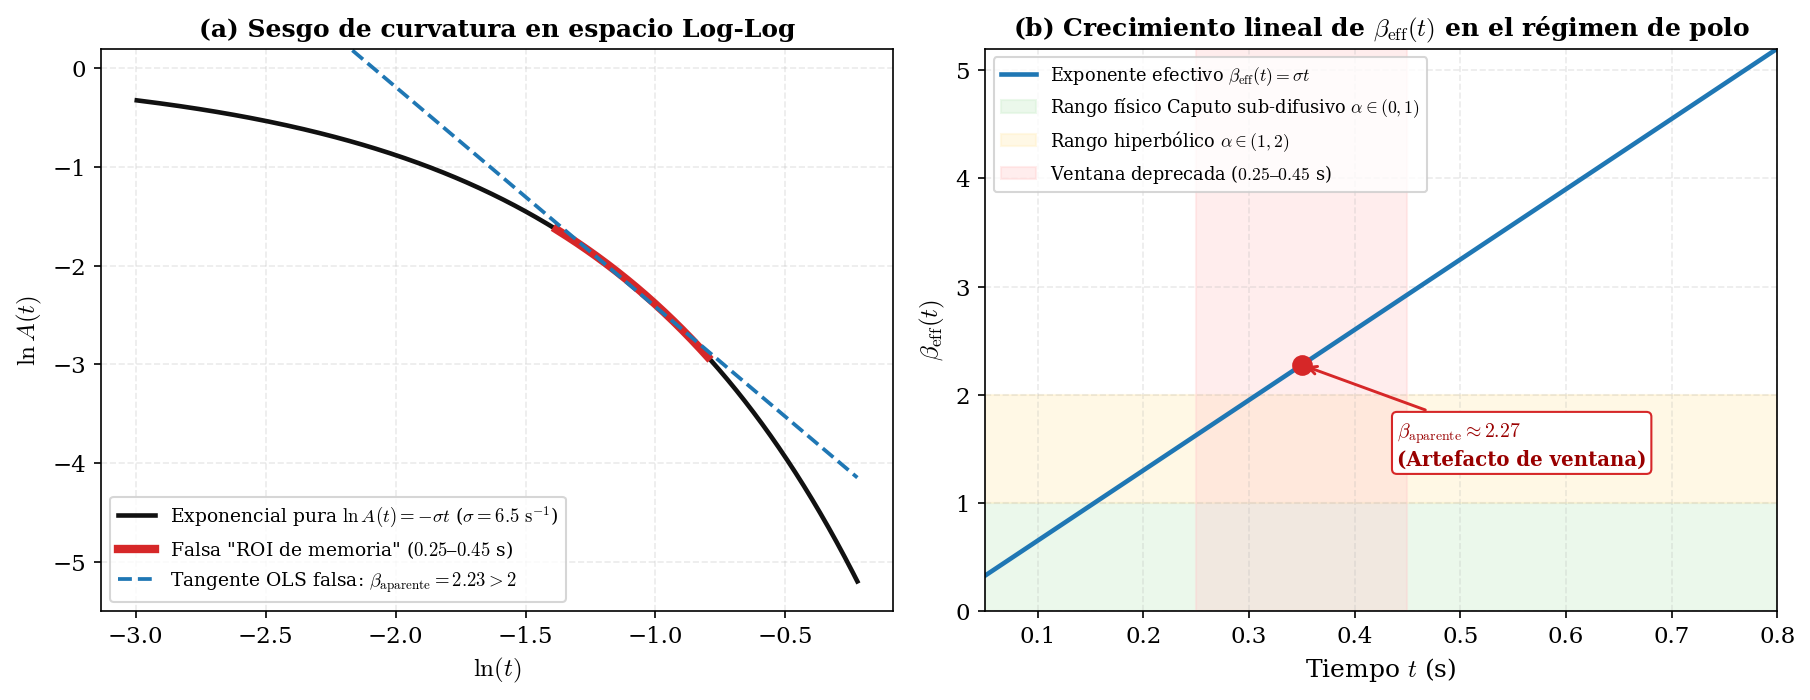

✅ Figura generada para Apéndice A: Fig_A_1_Diagnostico_Deprecado.pdf


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 12,
    'legend.fontsize': 9.0,
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--'
})

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.2, 4.8))

# Simulación limpia del envolvente exponencial puro (sigma = 6.5 s^-1, típico de dedo_mic)
t = np.linspace(0.05, 0.80, 500)
sigma_real = 6.5
ln_A = -sigma_real * t  # ln A(t) = -sigma * t (exponencial puro, SIN memoria fraccionaria)
ln_t = np.log(t)

# Ventana "ROI de Memoria" del pipeline antiguo: [0.25 s, 0.45 s]
mask_roi = (t >= 0.25) & (t <= 0.45)
p_falso = np.polyfit(ln_t[mask_roi], ln_A[mask_roi], 1)
beta_falso = -p_falso[0]  # ~ 2.24 (fuera del rango físico de Caputo 0 < alpha < 1)

# Panel (a): En espacio Log-Log, una exponencial pura se curva hacia abajo
ax1.plot(ln_t, ln_A, color='#111111', lw=2.2, label=r'Exponencial pura $\ln A(t) = -\sigma t$ ($\sigma=6.5\ \mathrm{s}^{-1}$)')
ax1.plot(ln_t[mask_roi], ln_A[mask_roi], color='#d62728', lw=4.0, label='Falsa "ROI de memoria" ($0.25\\text{–}0.45$ s)')
ax1.plot(ln_t, np.polyval(p_falso, ln_t), color='#1f77b4', ls='--', lw=1.8,
         label=rf'Tangente OLS falsa: $\beta_{{\mathrm{{aparente}}}} = {beta_falso:.2f} > 2$')

ax1.set_title('(a) Sesgo de curvatura en espacio Log-Log', fontweight='bold')
ax1.set_xlabel(r'$\ln(t)$')
ax1.set_ylabel(r'$\ln A(t)$')
ax1.set_ylim(-5.5, 0.2)
ax1.legend(loc='lower left', frameon=True)

# Panel (b): Estimador instantáneo beta_eff(t) = sigma * t cruzando la zona no física
ax2.plot(t, sigma_real * t, color='#1f77b4', lw=2.2, label=r'Exponente efectivo $\beta_{\mathrm{eff}}(t) = \sigma t$')
ax2.axhspan(0.0, 1.0, color='#d9f2d9', alpha=0.5, label=r'Rango físico Caputo sub-difusivo $\alpha \in (0, 1)$')
ax2.axhspan(1.0, 2.0, color='#fff2cc', alpha=0.5, label=r'Rango hiperbólico $\alpha \in (1, 2)$')
ax2.axvspan(0.25, 0.45, color='#ffcccc', alpha=0.35, label='Ventana deprecada ($0.25\\text{–}0.45$ s)')
ax2.scatter([0.35], [sigma_real * 0.35], color='#d62728', s=80, zorder=5)
ax2.annotate(rf'$\beta_{{\mathrm{{aparente}}}} \approx {sigma_real*0.35:.2f}$' + '\n(Artefacto de ventana)',
             xy=(0.35, sigma_real * 0.35), xytext=(0.44, 1.35),
             arrowprops=dict(arrowstyle='->', color='#d62728', lw=1.4),
             fontsize=9.5, fontweight='bold', color='#990000',
             bbox=dict(boxstyle='round,pad=0.25', facecolor='white', edgecolor='#d62728'))

ax2.set_title(r'(b) Crecimiento lineal de $\beta_{\mathrm{eff}}(t)$ en el régimen de polo', fontweight='bold')
ax2.set_xlabel(r'Tiempo $t$ (s)')
ax2.set_ylabel(r'$\beta_{\mathrm{eff}}(t)$')
ax2.set_xlim(0.05, 0.80)
ax2.set_ylim(0, 5.2)
ax2.legend(loc='upper left', frameon=True, fontsize=8.5)

plt.tight_layout()
plt.savefig('Fig_A_1_Diagnostico_Deprecado.pdf', bbox_inches='tight')
plt.savefig('Fig_A_1_Diagnostico_Deprecado.png', dpi=300, bbox_inches='tight')
plt.show()
print("✅ Figura generada para Apéndice A: Fig_A_1_Diagnostico_Deprecado.pdf")

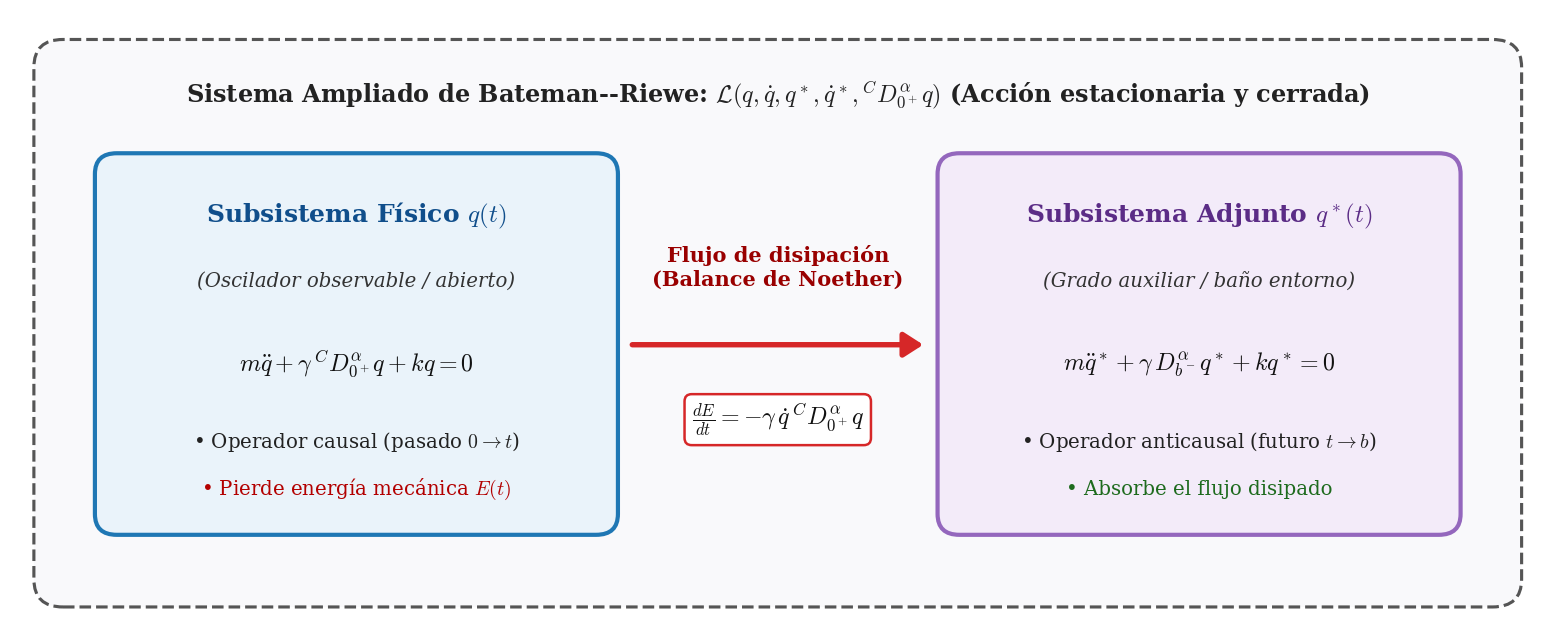

✅ Figura generada: Fig_4_1_Sistema_Bateman_Riewe.pdf


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as patches

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'cm',
    'font.size': 11,
    'figure.dpi': 150,
    'savefig.dpi': 300
})

fig, ax = plt.subplots(figsize=(10.5, 4.4))
ax.set_xlim(0, 10.5)
ax.set_ylim(0, 4.4)
ax.axis('off')

# Contenedor exterior: Sistema Ampliado Conservativo
outer_box = patches.FancyBboxPatch((0.25, 0.25), 10.0, 3.85,
                                   boxstyle="round,pad=0.12,rounding_size=0.2",
                                   linewidth=1.5, edgecolor='#555555',
                                   facecolor='#f9f9fb', linestyle='--', zorder=1)
ax.add_patch(outer_box)
ax.text(5.25, 3.82, r'Sistema Ampliado de Bateman--Riewe: $\mathcal{L}(q, \dot{q}, q^*, \dot{q}^*, {}^{C}D_{0^+}^\alpha q)$ (Acción estacionaria y cerrada)',
        ha='center', va='center', fontsize=11.5, fontweight='bold', color='#222222')

# Caja izquierda: Subsistema Físico q(t)
box_q = patches.FancyBboxPatch((0.65, 0.75), 3.4, 2.55,
                               boxstyle="round,pad=0.1,rounding_size=0.15",
                               linewidth=2.0, edgecolor='#1f77b4',
                               facecolor='#eaf3fa', zorder=2)
ax.add_patch(box_q)
ax.text(2.35, 2.95, r'Subsistema Físico $q(t)$', ha='center', va='center',
        fontsize=12, fontweight='bold', color='#104e8b')
ax.text(2.35, 2.48, r'(Oscilador observable / abierto)', ha='center', va='center',
        fontsize=9.5, style='italic', color='#333333')
ax.text(2.35, 1.88, r'$m\ddot{q} + \gamma\,{}^{C}D_{0^+}^{\alpha}q + kq = 0$',
        ha='center', va='center', fontsize=11.5, color='#111111')
ax.text(2.35, 1.32, r'• Operador causal (pasado $0 \to t$)', ha='center', va='center', fontsize=9.5, color='#222222')
ax.text(2.35, 0.98, r'• Pierde energía mecánica $E(t)$', ha='center', va='center', fontsize=9.5, color='#b30000')

# Caja derecha: Subsistema Adjunto q*(t)
box_qstar = patches.FancyBboxPatch((6.45, 0.75), 3.4, 2.55,
                                   boxstyle="round,pad=0.1,rounding_size=0.15",
                                   linewidth=2.0, edgecolor='#9467bd',
                                   facecolor='#f3ebf9', zorder=2)
ax.add_patch(box_qstar)
ax.text(8.15, 2.95, r'Subsistema Adjunto $q^*(t)$', ha='center', va='center',
        fontsize=12, fontweight='bold', color='#5b2c86')
ax.text(8.15, 2.48, r'(Grado auxiliar / baño entorno)', ha='center', va='center',
        fontsize=9.5, style='italic', color='#333333')
ax.text(8.15, 1.88, r'$m\ddot{q}^* + \gamma\,D_{b^-}^{\alpha}q^* + kq^* = 0$',
        ha='center', va='center', fontsize=11.5, color='#111111')
ax.text(8.15, 1.32, r'• Operador anticausal (futuro $t \to b$)', ha='center', va='center', fontsize=9.5, color='#222222')
ax.text(8.15, 0.98, r'• Absorbe el flujo disipado', ha='center', va='center', fontsize=9.5, color='#1e6b1e')

# Flecha central de flujo energético (Ley de Balance de Noether)
ax.annotate('', xy=(6.28, 2.02), xytext=(4.22, 2.02),
            arrowprops=dict(arrowstyle='-|>,head_length=0.7,head_width=0.45',
                            color='#d62728', lw=2.6), zorder=4)

ax.text(5.25, 2.58, 'Flujo de disipación\n(Balance de Noether)', ha='center', va='center',
        fontsize=10, fontweight='bold', color='#990000')
ax.text(5.25, 1.48, r'$\frac{dE}{dt} = -\gamma\,\dot{q}\,{}^{C}D_{0^+}^{\alpha}q$',
        ha='center', va='center', fontsize=11.5, color='#111111',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='white', edgecolor='#d62728', lw=1.2))

plt.tight_layout()
plt.savefig('Fig_4_1_Sistema_Bateman_Riewe.pdf', bbox_inches='tight')
plt.show()
print("✅ Figura generada: Fig_4_1_Sistema_Bateman_Riewe.pdf")